# Interpreting the NumPy MLP

Explore what the trained MNIST MLP has learned and how it responds to images:

- Visualize first-layer weights as 28 × 28 patterns.
- Inspect test-set performance and representative predictions.
- Compare hidden-layer activations across digit classes.
- Measure how masking image patches changes a prediction.

The model is loaded from `models/mnist_mlp.npz`, created by
`01_MLP_From_Scratch.ipynb`. This notebook uses the official test split for
descriptive analysis only; do not use these results to select hyperparameters.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.datasets import mnist

SEED = 42
rng = np.random.default_rng(SEED)

PROJECT_ROOT = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "pyproject.toml").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find pyproject.toml. Start Jupyter inside the project directory."
    )

ARTIFACT_PATH = PROJECT_ROOT / "models" / "mnist_mlp.npz"

plt.rcParams.update(
    {
        "figure.figsize": (10, 5),
        "image.cmap": "gray",
        "axes.titlesize": 10,
    }
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Model artifact: {ARTIFACT_PATH}")

Project root: c:\Users\hp\Documents\GitHub\multilayer-perceptron-from-scratch
Model artifact: c:\Users\hp\Documents\GitHub\multilayer-perceptron-from-scratch\models\mnist_mlp.npz


## Load the trained model

Run `01_MLP_From_Scratch.ipynb` first if the model artifact does not exist.
The saved arrays contain the model parameters and architecture dimensions.

In [7]:
if not ARTIFACT_PATH.is_file():
    raise FileNotFoundError(
        f"Model artifact not found: {ARTIFACT_PATH}\n"
        "Run notebooks/01_MLP_From_Scratch.ipynb to train and save the model."
    )

with np.load(ARTIFACT_PATH, allow_pickle=False) as artifact:
    required_keys = {
        "W1",
        "b1",
        "W2",
        "b2",
        "input_dim",
        "hidden_dim",
        "output_dim",
        "pixel_scale",
    }
    missing_keys = required_keys.difference(artifact.files)
    if missing_keys:
        raise ValueError(f"Model artifact is missing keys: {sorted(missing_keys)}")

    params = {
        name: artifact[name].astype(np.float32, copy=True)
        for name in ("W1", "b1", "W2", "b2")
    }
    input_dim = int(artifact["input_dim"])
    hidden_dim = int(artifact["hidden_dim"])
    output_dim = int(artifact["output_dim"])
    pixel_scale = float(artifact["pixel_scale"])
    saved_test_accuracy = (
        float(artifact["test_accuracy"])
        if "test_accuracy" in artifact.files
        else None
    )

assert input_dim == 28 * 28, f"Expected 784 inputs; got {input_dim}"
assert output_dim == 10, f"Expected 10 output classes; got {output_dim}"
assert pixel_scale > 0

assert params["W1"].shape == (input_dim, hidden_dim)
assert params["b1"].shape == (hidden_dim,)
assert params["W2"].shape == (hidden_dim, output_dim)
assert params["b2"].shape == (output_dim,)
assert all(np.isfinite(value).all() for value in params.values())

print(f"Architecture: {input_dim} → {hidden_dim} → {output_dim}")
print(f"Pixel scale:  {pixel_scale:g}")
if saved_test_accuracy is not None:
    print(f"Test accuracy recorded at training time: {saved_test_accuracy:.2%}")

Architecture: 784 → 128 → 10
Pixel scale:  255
Test accuracy recorded at training time: 96.67%


## Load MNIST and define inference helpers

TensorFlow is used only to load the dataset. The forward pass and softmax below use NumPy.
Images are flattened and normalized in batches to avoid creating an extra full-size float copy.

In [8]:
(_, _), (X_test, y_test) = mnist.load_data()

assert X_test.shape == (10_000, 28, 28)
assert y_test.shape == (10_000,)
assert set(np.unique(y_test)) == set(range(10))


def preprocess_images(images: np.ndarray) -> np.ndarray:
    """Flatten images and scale pixel values to the range expected by the model."""
    X = images.reshape(len(images), -1).astype(np.float32)
    X /= np.float32(pixel_scale)
    return X


def forward(X: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return output logits and first hidden-layer activations."""
    Z1 = X @ params["W1"] + params["b1"]
    A1 = np.maximum(Z1, 0)
    logits = A1 @ params["W2"] + params["b2"]
    return logits, A1


def softmax(logits: np.ndarray) -> np.ndarray:
    """Compute stable row-wise softmax probabilities."""
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_shifted = np.exp(shifted)
    return exp_shifted / exp_shifted.sum(axis=1, keepdims=True)


def predict_in_batches(
    images: np.ndarray,
    batch_size: int = 512,
) -> tuple[np.ndarray, np.ndarray]:
    """Return probabilities and hidden activations for a set of images."""
    probability_batches = []
    activation_batches = []

    for start in range(0, len(images), batch_size):
        batch_images = images[start : start + batch_size]
        X_batch = preprocess_images(batch_images)
        logits, activations = forward(X_batch)
        probability_batches.append(softmax(logits))
        activation_batches.append(activations)

    return (
        np.concatenate(probability_batches, axis=0),
        np.concatenate(activation_batches, axis=0),
    )


print(f"Test images: {X_test.shape}; labels: {y_test.shape}")

Test images: (10000, 28, 28); labels: (10000,)


## First-layer weight patterns

Each column of `W1` connects the 784 input pixels to one hidden unit.
Reshaping a column to 28 × 28 shows which input patterns increase or decrease
that unit's pre-activation. These are learned weights, not guaranteed to be
human-interpretable edge detectors.

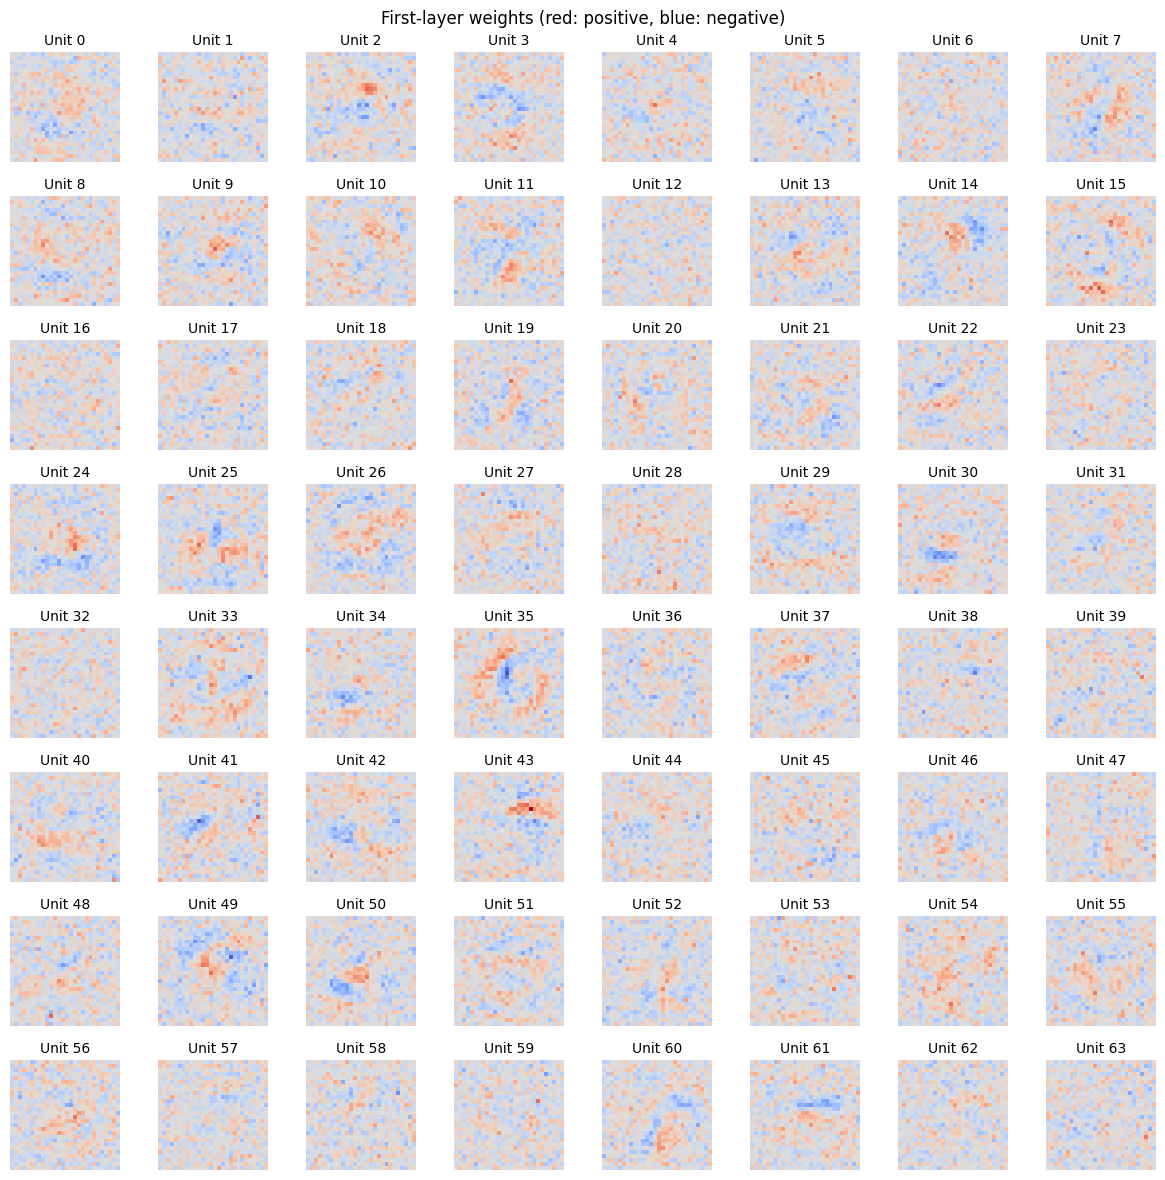

In [9]:
filters_to_show = min(64, hidden_dim)
columns = 8
rows = int(np.ceil(filters_to_show / columns))

weight_images = params["W1"][:, :filters_to_show].T.reshape(-1, 28, 28)
color_limit = float(np.max(np.abs(weight_images)))
if color_limit == 0:
    color_limit = 1.0

fig, axes = plt.subplots(rows, columns, figsize=(12, 1.5 * rows))
axes = np.asarray(axes).reshape(-1)

for unit, ax in enumerate(axes):
    if unit < filters_to_show:
        ax.imshow(
            weight_images[unit],
            vmin=-color_limit,
            vmax=color_limit,
            cmap="coolwarm",
        )
        ax.set_title(f"Unit {unit}")
    ax.axis("off")

fig.suptitle("First-layer weights (red: positive, blue: negative)")
fig.tight_layout()
plt.show()

## Test-set predictions and confusion matrix

Review aggregate errors by true and predicted digit. A confusion-matrix row is a true class;
a column is the model's predicted class.

In [10]:
test_probabilities, test_activations = predict_in_batches(X_test)
y_pred = np.argmax(test_probabilities, axis=1)
test_accuracy = float(np.mean(y_pred == y_test))

print(f"Test accuracy: {test_accuracy:.2%}")
if saved_test_accuracy is not None:
    print(
        "Saved training-notebook test accuracy: "
        f"{saved_test_accuracy:.2%}"
    )

print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(10),
        digits=3,
        zero_division=0,
    )
)

cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))
fig = px.imshow(
    cm,
    text_auto=True,
    aspect="auto",
    x=[str(digit) for digit in range(10)],
    y=[str(digit) for digit in range(10)],
    labels={"x": "Predicted digit", "y": "True digit", "color": "Count"},
    title="MNIST test-set confusion matrix",
    color_continuous_scale="Blues",
)
fig.show()

Test accuracy: 96.67%
Saved training-notebook test accuracy: 96.67%
              precision    recall  f1-score   support

           0      0.973     0.988     0.980       980
           1      0.984     0.989     0.987      1135
           2      0.949     0.977     0.963      1032
           3      0.966     0.965     0.966      1010
           4      0.962     0.974     0.968       982
           5      0.967     0.957     0.962       892
           6      0.965     0.973     0.969       958
           7      0.974     0.946     0.960      1028
           8      0.958     0.962     0.960       974
           9      0.967     0.933     0.950      1009

    accuracy                          0.967     10000
   macro avg      0.967     0.966     0.966     10000
weighted avg      0.967     0.967     0.967     10000



## Inspect individual predictions

The first grid shows correctly classified examples; the second shows errors when available.
The bar chart reports class probabilities for the selected image, not a calibrated measure
of certainty.

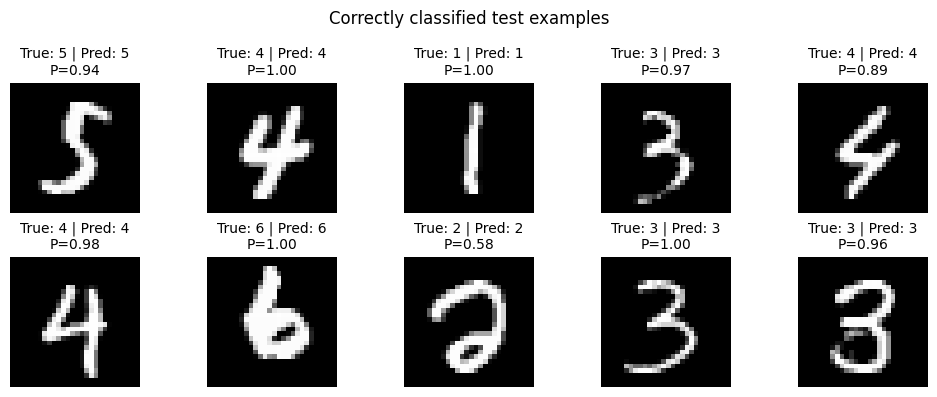

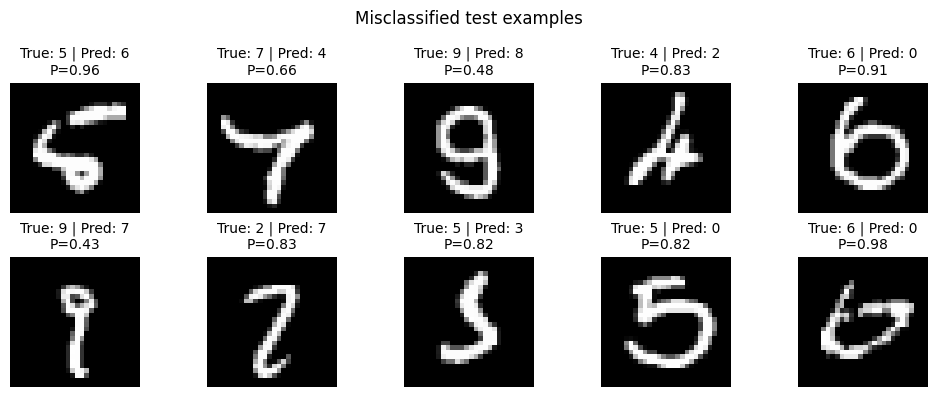

In [11]:
correct_indices = np.flatnonzero(y_pred == y_test)
incorrect_indices = np.flatnonzero(y_pred != y_test)

if len(correct_indices) == 0:
    raise RuntimeError("No correctly classified test examples were found.")

selected_correct = rng.choice(
    correct_indices,
    size=min(10, len(correct_indices)),
    replace=False,
)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, index in zip(axes.flat, selected_correct):
    ax.imshow(X_test[index], vmin=0, vmax=255)
    ax.set_title(
        f"True: {y_test[index]} | Pred: {y_pred[index]}\n"
        f"P={test_probabilities[index, y_pred[index]]:.2f}"
    )
    ax.axis("off")

fig.suptitle("Correctly classified test examples")
fig.tight_layout()
plt.show()

if len(incorrect_indices) > 0:
    selected_incorrect = incorrect_indices[: min(10, len(incorrect_indices))]
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))

    for ax, index in zip(axes.flat, selected_incorrect):
        ax.imshow(X_test[index], vmin=0, vmax=255)
        ax.set_title(
            f"True: {y_test[index]} | Pred: {y_pred[index]}\n"
            f"P={test_probabilities[index, y_pred[index]]:.2f}"
        )
        ax.axis("off")

    for ax in axes.flat[len(selected_incorrect) :]:
        ax.axis("off")

    fig.suptitle("Misclassified test examples")
    fig.tight_layout()
    plt.show()
else:
    print("No misclassified test examples.")

## Examine one prediction's class probabilities

Set `SAMPLE_INDEX` to any index from 0 to 9,999. The displayed probability vector
shows how the model distributes its output across the ten classes.

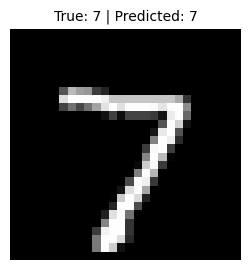

True label:      7
Predicted label: 7
Top probability: 0.997


In [12]:
SAMPLE_INDEX = 0

if not 0 <= SAMPLE_INDEX < len(y_test):
    raise IndexError(f"SAMPLE_INDEX must be between 0 and {len(y_test) - 1}")

sample_probabilities = test_probabilities[SAMPLE_INDEX]
sample_prediction = int(np.argmax(sample_probabilities))

plt.figure(figsize=(3, 3))
plt.imshow(X_test[SAMPLE_INDEX], vmin=0, vmax=255)
plt.title(
    f"True: {y_test[SAMPLE_INDEX]} | "
    f"Predicted: {sample_prediction}"
)
plt.axis("off")
plt.show()

fig = go.Figure(
    go.Bar(
        x=np.arange(10),
        y=sample_probabilities,
        marker_color=[
            "#2ca02c" if digit == y_test[SAMPLE_INDEX] else "#4c78a8"
            for digit in range(10)
        ],
    )
)
fig.update_layout(
    title="Output probabilities",
    xaxis_title="Digit class",
    yaxis_title="Probability",
    xaxis=dict(tickmode="linear", dtick=1),
    yaxis=dict(range=[0, 1]),
)
fig.show()

print(f"True label:      {y_test[SAMPLE_INDEX]}")
print(f"Predicted label: {sample_prediction}")
print(f"Top probability: {sample_probabilities[sample_prediction]:.3f}")

## Hidden-layer activity by digit

For each digit, compute the mean ReLU activation of every hidden unit across its test examples.
The heatmap can reveal units that respond more strongly to some classes than others, but
does not by itself establish what feature a unit represents.

In [13]:
activation_means = np.zeros((10, hidden_dim), dtype=np.float64)
class_counts = np.bincount(y_test, minlength=10)

for digit in range(10):
    activation_means[digit] = test_activations[y_test == digit].mean(axis=0)

fig = px.imshow(
    activation_means,
    aspect="auto",
    x=[f"Unit {unit}" for unit in range(hidden_dim)],
    y=[str(digit) for digit in range(10)],
    labels={
        "x": "Hidden unit",
        "y": "True digit",
        "color": "Mean ReLU activation",
    },
    title="Mean hidden-layer activation by true digit",
    color_continuous_scale="Viridis",
)
fig.show()

print("Test examples per digit:", class_counts.tolist())

Test examples per digit: [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]


## Occlusion sensitivity for one image

Mask each 4 × 4 region with zero-valued pixels and measure the change in the selected
class probability. Larger positive values mean masking that region reduced the probability.

This is a simple perturbation analysis, not a causal explanation. Results depend on the
chosen image, patch size, and masking value.

In [14]:
OCCLUSION_SAMPLE_INDEX = SAMPLE_INDEX
PATCH_SIZE = 4
STRIDE = 2

image = X_test[OCCLUSION_SAMPLE_INDEX].astype(np.float32)
image /= np.float32(pixel_scale)

baseline_probabilities, _ = predict_in_batches(
    X_test[OCCLUSION_SAMPLE_INDEX : OCCLUSION_SAMPLE_INDEX + 1]
)
target_class = int(np.argmax(baseline_probabilities[0]))
baseline_probability = float(baseline_probabilities[0, target_class])

locations = [
    (top, left)
    for top in range(0, 28 - PATCH_SIZE + 1, STRIDE)
    for left in range(0, 28 - PATCH_SIZE + 1, STRIDE)
]

occluded_images = np.repeat(image[None, :, :], len(locations), axis=0)

for index, (top, left) in enumerate(locations):
    occluded_images[
        index,
        top : top + PATCH_SIZE,
        left : left + PATCH_SIZE,
    ] = 0.0

occluded_logits, _ = forward(occluded_images.reshape(len(locations), -1))
occluded_probabilities = softmax(occluded_logits)[:, target_class]
probability_drop = baseline_probability - occluded_probabilities

sensitivity = np.zeros(
    (
        (28 - PATCH_SIZE) // STRIDE + 1,
        (28 - PATCH_SIZE) // STRIDE + 1,
    ),
    dtype=np.float32,
)

for (top, left), drop in zip(locations, probability_drop):
    sensitivity[top // STRIDE, left // STRIDE] = drop

fig = px.imshow(
    sensitivity,
    aspect="equal",
    labels={
        "x": "Patch left position (step units)",
        "y": "Patch top position (step units)",
        "color": "Probability drop",
    },
    title=f"Occlusion sensitivity for predicted class {target_class}",
    color_continuous_scale="RdBu",
    color_continuous_midpoint=0,
)
fig.show()

print(f"Selected image index: {OCCLUSION_SAMPLE_INDEX}")
print(f"Target class:         {target_class}")
print(f"Baseline probability: {baseline_probability:.3f}")
print(
    "Largest probability drop from masking one patch: "
    f"{float(np.max(probability_drop)):.3f}"
)

Selected image index: 0
Target class:         7
Baseline probability: 0.997
Largest probability drop from masking one patch: 0.025


## Interpretation notes

- First-layer weights visualize learned input patterns, but individual units may not have a
  simple semantic interpretation.
- Confusion matrices and example errors show where the classifier struggles.
- Hidden activations summarize unit responses across examples; correlation with a class
  does not prove a unit detects that digit.
- Occlusion sensitivity measures prediction changes under a specific masking perturbation.
  It is not a guaranteed causal or complete feature attribution.
- Keep the official test set for descriptive reporting rather than repeated model selection.

Next: explore the loss surface and optimization trajectory in `04_3D_Loss_Landscape.ipynb`.
``